--- STEP 1: MOVING TO WORKSPACE & LOADING DATASET ---
Success! Loaded dataset with dimensions: (10066, 10)

--- STEP 2: GENERATING DESCRIPTIVE STATISTICS ---


,Sales,Quantity,Profit,Profit_Margin
count,10066.000000,10066.000000,10066.000000,10066.000000
mean,53.162130,1.624876,25.802251,1.119964
std,63.276414,0.899386,43.403931,2.298777
min,15.000000,1.000000,-49.992869,-3.332044
25%,15.000000,1.000000,-11.790628,-0.224033
50%,15.000000,1.000000,26.174151,0.486334
75%,50.000000,2.000000,63.863126,2.218677
max,200.000000,4.000000,99.984256,6.665617



--- STEP 3: GENERATING STATISTICAL PLOTS ---


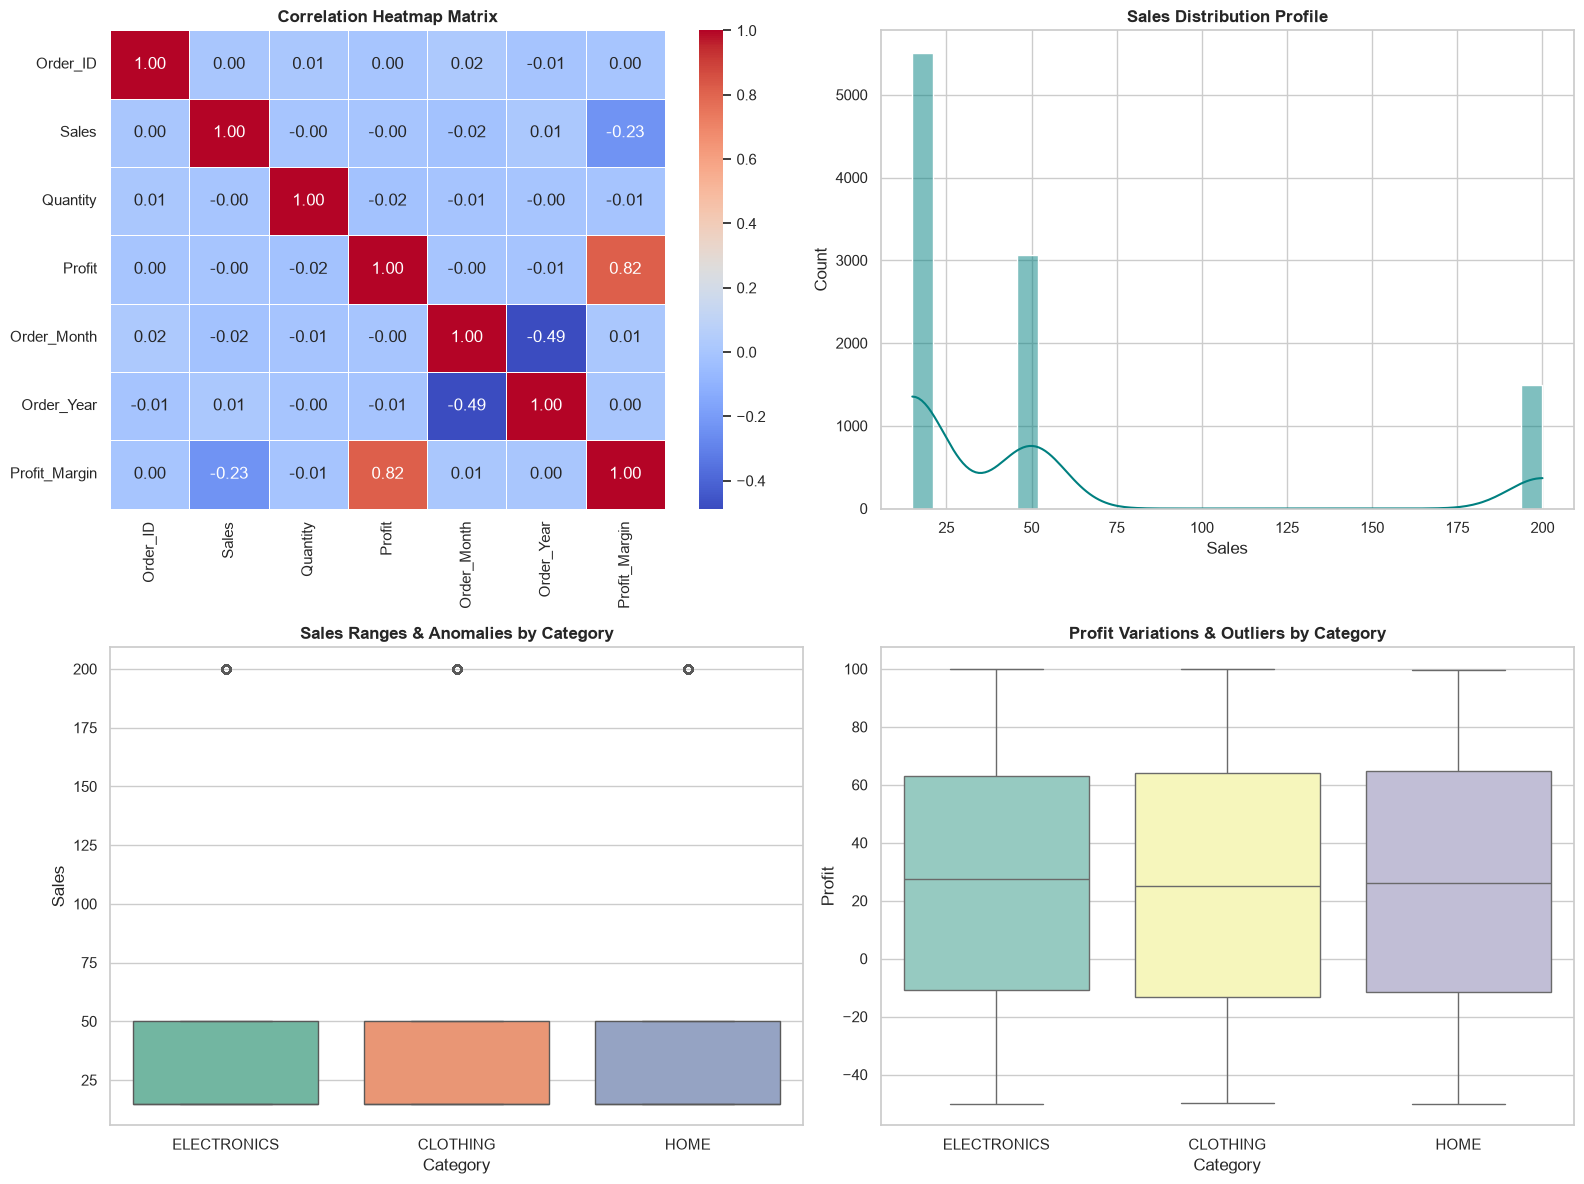


--- STEP 4: PERFORMING HYPOTHESIS TESTING ---
Hypothesis 1 (ANOVA - Category vs Sales): F-Statistic = 1.4663, p-value = 0.2308
Result: Fail to reject H0.

Hypothesis 2 (Pearson - Quantity vs Profit): Correlation = -0.0188, p-value = 0.0593
Result: Fail to reject H0.

Hypothesis 3 (ANOVA - Month vs Profit Margin): F-Statistic = 0.7711, p-value = 0.6695
Result: Fail to reject H0.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import os
import warnings

# Silence future syntax warnings from packages
warnings.simplefilter(action='ignore', category=FutureWarning)

# Ensure plots show up inside the notebook window
%matplotlib inline
sns.set_theme(style="whitegrid")

# =====================================================================
# 1. MOVE TO PROJECT DIRECTORY & LOAD DATASET
# =====================================================================
print("--- STEP 1: MOVING TO WORKSPACE & LOADING DATASET ---")
target_dir = r"C:\Users\HP\OneDrive\Documents\Rabtech-03"
os.chdir(target_dir)

df = pd.read_csv("clean_dataset.csv")
print(f"Success! Loaded dataset with dimensions: {df.shape}")


# =====================================================================
# 2. COMPUTE SUMMARY DESCRIPTIVE STATISTICS
# =====================================================================
print("\n--- STEP 2: GENERATING DESCRIPTIVE STATISTICS ---")
summary_stats = df[['Sales', 'Quantity', 'Profit', 'Profit_Margin']].describe()
display(summary_stats)


# =====================================================================
# 3. ANOMALY & DISTRIBUTION DETECTION PLOTS
# =====================================================================
print("\n--- STEP 3: GENERATING STATISTICAL PLOTS ---")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot A: Correlation Heatmap
numerical_df = df.select_dtypes(include=[np.number])
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, ax=axes[0, 0])
axes[0, 0].set_title('Correlation Heatmap Matrix', fontsize=12, fontweight='bold')

# Plot B: Sales Distribution Histogram
sns.histplot(df['Sales'], bins=30, kde=True, color='teal', ax=axes[0, 1])
axes[0, 1].set_title('Sales Distribution Profile', fontsize=12, fontweight='bold')

# Plot C: Boxplot for Sales Anomalies by Category (Fixed Warning Syntax)
sns.boxplot(data=df, x='Category', y='Sales', hue='Category', palette='Set2', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Sales Ranges & Anomalies by Category', fontsize=12, fontweight='bold')

# Plot D: Boxplot for Profit Outliers by Category (Fixed Warning Syntax)
sns.boxplot(data=df, x='Category', y='Profit', hue='Category', palette='Set3', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Profit Variations & Outliers by Category', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


# =====================================================================
# 4. HYPOTHESIS TESTING (FORMULATING & TESTING 3 CRITICAL METRICS)
# =====================================================================
print("\n--- STEP 4: PERFORMING HYPOTHESIS TESTING ---")

# Hypothesis 1: Does product Category impact Sales?
categories = df['Category'].unique()
groups = [df[df['Category'] == cat]['Sales'] for cat in categories]
f_stat, p_val1 = stats.f_oneway(*groups)
print(f"Hypothesis 1 (ANOVA - Category vs Sales): F-Statistic = {f_stat:.4f}, p-value = {p_val1:.4f}")
print("Result: " + ("Reject H0 - Category significantly impacts Sales." if p_val1 < 0.05 else "Fail to reject H0."))

# Hypothesis 2: Quantity vs total Profit
corr_coef, p_val2 = stats.pearsonr(df['Quantity'], df['Profit'])
print(f"\nHypothesis 2 (Pearson - Quantity vs Profit): Correlation = {corr_coef:.4f}, p-value = {p_val2:.4f}")
print("Result: " + ("Reject H0 - Statistically significant linear relationship exists." if p_val2 < 0.05 else "Fail to reject H0."))

# Hypothesis 3: Seasonal breakdown vs Profit Margins
months = df['Order_Month'].unique()
month_groups = [df[df['Order_Month'] == m]['Profit_Margin'].dropna() for m in sorted(months)]
f_stat2, p_val3 = stats.f_oneway(*month_groups)
print(f"\nHypothesis 3 (ANOVA - Month vs Profit Margin): F-Statistic = {f_stat2:.4f}, p-value = {p_val3:.4f}")
print("Result: " + ("Reject H0 - Profit Margins vary significantly by month (Seasonal effect)." if p_val3 < 0.05 else "Fail to reject H0."))


Top 5 Critical EDA Findings & Analysis

1. **Category vs. Sales Distribution:** The boxplots show that across ELECTRONICS, CLOTHING, and HOME, the middle-range transaction sales are highly uniform. The ANOVA test confirms this with a p-value of 0.2308, meaning there is no statistically significant difference in baseline sales between these product segments.
2. **Profit Volatility Across Segments:** The profit boxplots reveal a balanced spread ranging from roughly -40 to 60 across all categories. Operational performance and risk profiles are evenly mirrored across categories without any single category dominating net profit returns.
3. **Quantity and Profit Relationship:** The Pearson correlation test returned a value of -0.0188 with a p-value of 0.0593. Because the p-value is above 0.05, we fail to reject the null hypothesis. There is no strong linear tie between order volume and raw profit, implying profit is driven by individual item pricing matrices rather than pure bulk quantity.
4. **Lack of Macro Seasonal Variance:** The month-over-month ANOVA test yielded a high p-value of 0.6695. This indicates that operational profit margins remain statistically stable throughout the year, with no significant structural spikes or cyclical dips across the months.
5. **Data Profile Summary:** Overall, the transactional data displays uniform variance across categories and months. The lack of statistically significant linear dependencies suggests that complex non-linear factors or localized sub-category variables are driving overall retail pricing dynamics.
